# Fine-tune a pretrained CNN on ISIC 2020 (RTX 5070, 12 GB)

Uses the cache made by `preprocess_jpeg.ipynb`. `isic_utils.py` must be in the same folder.

**One-time setup (Miniconda prompt).** The RTX 5070 is a Blackwell GPU, so PyTorch must be built for **CUDA 12.8 (`cu128`)**; older builds fail with *"no kernel image is available"*.
```
conda create -n isic python=3.11 -y
conda activate isic
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
pip install numpy pandas scikit-learn matplotlib tqdm pillow jupyter ipywidgets
python -m ipykernel install --user --name isic
```
Then open Jupyter and pick the **isic** kernel.

**Training-time preprocessing** (in `isic_utils.py`): random resized crop, horizontal + vertical flips, 90° rotations, mild color jitter, light blur, then **ImageNet mean/std normalization** (required for pretrained weights). Validation/test: resize + normalize only.

**Class imbalance (~1.8% melanoma):** `BCEWithLogitsLoss` with `pos_weight`. Model selection uses **validation AUPRC**. The test set is touched only when `RUN_FINAL_TEST = True`.

In [8]:
from pathlib import Path
import json, math, sys, time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import isic_utils as U

# ------------------------------------------------------------------ settings
CACHE_DIR      = ROOT / 'artifacts' / 'jpeg_256'   # folder written by preprocess_jpeg.ipynb
MODEL_NAME     = 'resnet50'      # resnet50 | resnet18 | efficientnet_b0 | densenet121
PRETRAINED     = True            # False = the 'CNN from scratch' baseline (train longer, e.g. 40 epochs)
SPLIT          = 'patient'       # 'patient' (main) or 'random' (leakage comparison)
TRAIN_FRACTION = 1.0             # 0.25 / 0.5 / 0.75 / 1.0 for the data-size study (samples patients)
IMG_SIZE       = 224
EPOCHS         = 15
BATCH_SIZE     = 64
LR             = 2e-4
WEIGHT_DECAY   = 1e-4
POS_WEIGHT     = None            # None = sqrt(neg/pos) (~7). Set 1.0 to switch off.
PATIENCE       = 5               # early stopping on val AUPRC
NUM_WORKERS    = 4               # set 0 if the DataLoader hangs on Windows
SEED           = 42
RUN_FINAL_TEST = True           # True only once, at the very end of the project

RUN_NAME = f'{MODEL_NAME}_{"pt" if PRETRAINED else "scratch"}_{SPLIT}_f{TRAIN_FRACTION}_s{SEED}'
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
if device.type == 'cuda':
    print('compute capability:', torch.cuda.get_device_capability(0), '| arch list:', torch.cuda.get_arch_list())
    torch.backends.cudnn.benchmark = True
AMP_DTYPE = torch.bfloat16 if device.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float16
print('run:', RUN_DIR)

torch 2.11.0+cu128 | device: cuda | NVIDIA GeForce RTX 5070
compute capability: (12, 0) | arch list: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
run: C:\Users\mahmu\OneDrive\Desktop\Computer Vision\Project\runs\resnet50_pt_patient_f1.0_s42


## Data

In [2]:
meta = pd.read_csv(CACHE_DIR / 'metadata.csv')
cache_path = CACHE_DIR / 'images_uint8.npy'
assert json.loads((CACHE_DIR / 'manifest.json').read_text())['complete'], 'Run preprocess_jpeg.ipynb first'

col = f'split_{SPLIT}'
tr_df, va_df, te_df = (meta[meta[col] == s] for s in ['train', 'val', 'test'])

if TRAIN_FRACTION < 1.0:   # keep whole patients, stratified by whether the patient has melanoma
    from sklearn.model_selection import train_test_split
    pat = tr_df.groupby('patient_id')['target'].max()
    keep, _ = train_test_split(pat.index, train_size=TRAIN_FRACTION, stratify=pat.values, random_state=SEED)
    tr_df = tr_df[tr_df.patient_id.isin(keep)]

for name, d in [('train', tr_df), ('val', va_df), ('test', te_df)]:
    print(f'{name:5s}: {len(d):6d} images | {int(d.target.sum()):4d} melanoma | {d.patient_id.nunique()} patients')

def make_loader(d, train):
    ds = U.CachedISIC(cache_path, d['cache_index'].values, d['target'].values, U.build_transforms(IMG_SIZE, train))
    return DataLoader(ds, batch_size=BATCH_SIZE if train else BATCH_SIZE * 2, shuffle=train, drop_last=train,
                      num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)

train_loader, val_loader = make_loader(tr_df, True), make_loader(va_df, False)
x, y = next(iter(train_loader))
print('batch:', tuple(x.shape), x.dtype, '| melanoma in batch:', int(y.sum()))

train:  23364 images |  414 melanoma | 1469 patients
val  :   4663 images |   85 melanoma | 292 patients
test :   4674 images |   82 melanoma | 295 patients
batch: (64, 3, 224, 224) torch.float32 | melanoma in batch: 1


## Model, loss, optimizer

In [3]:
model = U.build_model(MODEL_NAME, PRETRAINED).to(device).to(memory_format=torch.channels_last)

n_pos, n_neg = tr_df.target.sum(), len(tr_df) - tr_df.target.sum()
pw = math.sqrt(n_neg / n_pos) if POS_WEIGHT is None else POS_WEIGHT
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw, device=device))
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

steps = EPOCHS * len(train_loader); warm = len(train_loader)          # 1 epoch linear warm-up, then cosine
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
scaler = torch.amp.GradScaler('cuda', enabled=(AMP_DTYPE == torch.float16 and device.type == 'cuda'))

print(f'{MODEL_NAME}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M params | pos_weight = {pw:.2f}')

@torch.no_grad()
def predict(loader):
    model.eval(); probs, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=device.type == 'cuda'):
            probs.append(torch.sigmoid(model(x).float().squeeze(1)).cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(probs).numpy()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\mahmu/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:04<00:00, 22.3MB/s]


resnet50: 23.5M params | pos_weight = 7.45


## Train (best checkpoint = highest validation AUPRC)

In [4]:
history, best, bad_epochs = [], -1.0, 0
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); run_loss = 0.0
    for x, y in tqdm(train_loader, desc=f'epoch {epoch}', leave=False):
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=device.type == 'cuda'):
            loss = criterion(model(x).squeeze(1).float(), y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
        run_loss += loss.item()
    yv, pv = predict(val_loader)
    m = U.compute_metrics(yv, pv, U.best_f1_threshold(yv, pv))
    row = {'epoch': epoch, 'train_loss': run_loss / len(train_loader), 'val_AUPRC': m['AUPRC'],
           'val_AUROC': m['AUROC'], 'val_recall': m['recall_melanoma'], 'minutes': (time.time() - t0) / 60}
    history.append(row); pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)
    print(' | '.join(f'{k} {v:.4f}' if isinstance(v, float) else f'{k} {v}' for k, v in row.items()))
    if m['AUPRC'] > best:
        best, bad_epochs = m['AUPRC'], 0
        torch.save(model.state_dict(), RUN_DIR / 'best.pt')
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print('early stop'); break
print(f'best val AUPRC = {best:.4f}')

epoch 1:   0%|          | 0/365 [00:00<?, ?it/s]

epoch 1 | train_loss 0.4026 | val_AUPRC 0.0888 | val_AUROC 0.8348 | val_recall 0.1765 | minutes 1.3120


epoch 2:   0%|          | 0/365 [00:00<?, ?it/s]

epoch 2 | train_loss 0.3202 | val_AUPRC 0.1301 | val_AUROC 0.8786 | val_recall 0.4235 | minutes 0.9024


epoch 3:   0%|          | 0/365 [00:00<?, ?it/s]

...

epoch 13 | train_loss 0.1528 | val_AUPRC 0.3156 | val_AUROC 0.9309 | val_recall 0.5882 | minutes 0.8785


epoch 14:   0%|          | 0/365 [00:00<?, ?it/s]

epoch 14 | train_loss 0.1497 | val_AUPRC 0.3060 | val_AUROC 0.9289 | val_recall 0.5647 | minutes 0.8745


epoch 15:   0%|          | 0/365 [00:00<?, ?it/s]

epoch 15 | train_loss 0.1444 | val_AUPRC 0.2975 | val_AUROC 0.9273 | val_recall 0.5176 | minutes 0.8747
best val AUPRC = 0.3156


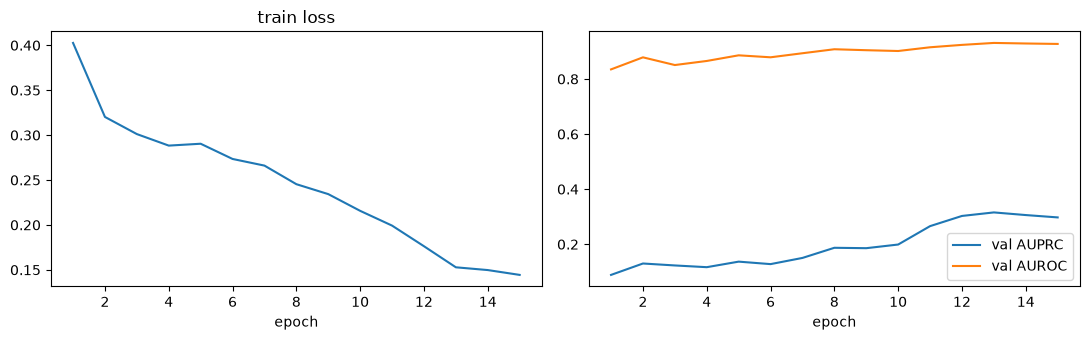

In [5]:
import matplotlib.pyplot as plt
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss); ax[0].set_title('train loss'); ax[0].set_xlabel('epoch')
ax[1].plot(h.epoch, h.val_AUPRC, label='val AUPRC'); ax[1].plot(h.epoch, h.val_AUROC, label='val AUROC')
ax[1].legend(); ax[1].set_xlabel('epoch'); plt.tight_layout(); plt.show()

## Validation results + efficiency
The decision threshold is chosen on **validation** (best F1) and reused unchanged on test.

In [6]:
model.load_state_dict(torch.load(RUN_DIR / 'best.pt', map_location=device))
yv, pv = predict(val_loader)
THRESHOLD = U.best_f1_threshold(yv, pv)
val_metrics = U.compute_metrics(yv, pv, THRESHOLD)

eff = {'params_M': sum(p.numel() for p in model.parameters()) / 1e6,
       'size_MB_fp32': U.model_size_mb(model),
       'ms_per_image_bs1': U.time_per_image_ms(model, IMG_SIZE, device, batch_size=1),
       'ms_per_image_bs64': U.time_per_image_ms(model, IMG_SIZE, device, batch_size=64, n_iter=20)}
pd.DataFrame({'image_name': va_df.image_name.values, 'patient_id': va_df.patient_id.values,
              'target': yv, 'prob': pv}).to_csv(RUN_DIR / 'val_predictions.csv', index=False)
(RUN_DIR / 'val_metrics.json').write_text(json.dumps({**val_metrics, **eff}, indent=2))
display(pd.Series({**val_metrics, **eff}).round(4).to_frame('validation'))

,validation
AUPRC,0.3156
AUROC,0.9309
balanced_acc,0.7818
recall_melanoma,0.5882
F1,0.4032
threshold,0.5368
TP,50.0000
FP,113.0000
FN,35.0000
TN,4465.0000


## Final test (run once, at the end)
Patient-level bootstrap 95% CIs. Predictions are saved for the error analysis.

In [9]:
if RUN_FINAL_TEST:
    yt, pt = predict(make_loader(te_df, False))
    test_metrics = U.compute_metrics(yt, pt, THRESHOLD)
    ci = U.bootstrap_ci(yt, pt, groups=te_df.patient_id.values, n_boot=1000, threshold=THRESHOLD)
    pd.DataFrame({'image_name': te_df.image_name.values, 'patient_id': te_df.patient_id.values,
                  'target': yt, 'prob': pt}).to_csv(RUN_DIR / 'test_predictions.csv', index=False)
    (RUN_DIR / 'test_metrics.json').write_text(json.dumps({**test_metrics, 'CI95': ci}, indent=2))
    out = pd.Series(test_metrics).to_frame('test')
    out['CI95'] = [ci.get(k, '') for k in out.index]
    display(out)
else:
    print('Test set not touched. Set RUN_FINAL_TEST = True only for the final evaluation.')

,test,CI95
AUPRC,0.203015,"(0.13444407447094023, 0.3029298882503067)"
AUROC,0.928522,"(0.9031191772686393, 0.9490434143299917)"
balanced_acc,0.729421,"(0.6681753404897423, 0.7874262351303298)"
recall_melanoma,0.487805,"(0.36244912790697675, 0.6060989643268124)"
F1,0.313725,"(0.22419645764962298, 0.3987850467289719)"
threshold,0.536799,
TP,40.000000,
FP,133.000000,
FN,42.000000,
TN,4459.000000,


model size and speed

In [16]:
import os

model.eval()
n_params  = sum(p.numel() for p in model.parameters())
n_nonzero = sum(int((p != 0).sum()) for p in model.parameters())   # will drop after pruning

peak_mb = float('nan')
if device.type == 'cuda':
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        model(torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device))
    peak_mb = torch.cuda.max_memory_allocated() / 1024**2

size_info = pd.Series({
    'Model': MODEL_NAME,
    'Parameters (M)': round(n_params / 1e6, 2),
    'Non-zero parameters (M)': round(n_nonzero / 1e6, 2),
    'Size in memory, FP32 (MB)': round(U.model_size_mb(model), 2),
    'Checkpoint file best.pt (MB)': round(os.path.getsize(RUN_DIR / 'best.pt') / 1024**2, 2),
    'Expected INT8 size (MB, approx.)': round(n_params / 1024**2, 2),
    'GPU time per image, batch 1 (ms)': round(U.time_per_image_ms(model, IMG_SIZE, device, 1), 3),
    'GPU time per image, batch 64 (ms)': round(U.time_per_image_ms(model, IMG_SIZE, device, 64, n_iter=20), 3),
    'Peak GPU memory, 1 image (MB)': round(peak_mb, 1),
})
size_info.to_frame('value').to_csv(RUN_DIR / 'model_size.csv')
display(size_info.to_frame('value'))

import copy
torch.set_num_threads(6)                    
cpu_model = copy.deepcopy(model).cpu().eval()
size_info['CPU time per image, batch 1 (ms)'] = round(U.time_per_image_ms(cpu_model, IMG_SIZE, torch.device('cpu'), 1, n_iter=30), 2)
del cpu_model
display(size_info.to_frame('value'))

,value
Model,resnet50
Parameters (M),23.51
Non-zero parameters (M),23.51
"Size in memory, FP32 (MB)",89.89
Checkpoint file best.pt (MB),89.97
"Expected INT8 size (MB, approx.)",22.42
"GPU time per image, batch 1 (ms)",4.584
"GPU time per image, batch 64 (ms)",0.749
"Peak GPU memory, 1 image (MB)",433.7


,value
Model,resnet50
Parameters (M),23.51
Non-zero parameters (M),23.51
"Size in memory, FP32 (MB)",89.89
Checkpoint file best.pt (MB),89.97
"Expected INT8 size (MB, approx.)",22.42
"GPU time per image, batch 1 (ms)",4.584
"GPU time per image, batch 64 (ms)",0.749
"Peak GPU memory, 1 image (MB)",433.7
"CPU time per image, batch 1 (ms)",30.16


full results table (train, val, test)

In [12]:
# Predictions for every split (train is evaluated without augmentation)
preds = {
    'train': predict(make_loader(tr_df, False)),
    'val':   predict(val_loader),
    'test':  (yt, pt) if 'yt' in globals() else predict(make_loader(te_df, False)),
}

rows = {}
for split, (y, p) in preds.items():
    m = U.compute_metrics(y, p, THRESHOLD)
    tp, fp, fn, tn = m['TP'], m['FP'], m['FN'], m['TN']
    rows[split] = {
        'Images': len(y), 'Melanoma': int(y.sum()),
        'AUPRC': m['AUPRC'], 'AUROC': m['AUROC'],
        'Balanced acc': m['balanced_acc'],
        'Recall (sensitivity)': m['recall_melanoma'],
        'Specificity': tn / (tn + fp) if tn + fp else float('nan'),
        'Precision': tp / (tp + fp) if tp + fp else float('nan'),
        'F1': m['F1'],
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }
results = pd.DataFrame(rows).T
results.index.name = f'{MODEL_NAME} | threshold={THRESHOLD:.3f} (chosen on val)'

# 95% CI for test (bootstrap over patients)
if 'ci' not in globals():
    ci = U.bootstrap_ci(*preds['test'], groups=te_df.patient_id.values, n_boot=1000, threshold=THRESHOLD)
ci_names = {'AUPRC': 'AUPRC', 'AUROC': 'AUROC', 'Balanced acc': 'balanced_acc',
            'Recall (sensitivity)': 'recall_melanoma', 'F1': 'F1'}
ci_row = {c: f'[{ci[k][0]:.3f}, {ci[k][1]:.3f}]' for c, k in ci_names.items()}
results_display = results.copy().astype(object)
for c in results.columns:
    if c not in ['Images', 'Melanoma', 'TP', 'FP', 'FN', 'TN']:
        results_display[c] = results[c].astype(float).round(4)
results_display.loc['test 95% CI'] = [ci_row.get(c, '') for c in results.columns]

results.to_csv(RUN_DIR / 'results_all_splits.csv')
display(results_display)

,Images,Melanoma,AUPRC,AUROC,Balanced acc,Recall (sensitivity),Specificity,Precision,F1,TP,FP,FN,TN
resnet50 | threshold=0.537 (chosen on val),,,,,,,,,,,,,
train,23364.0,414.0,0.592,0.9821,0.8797,0.7826,0.9767,0.3776,0.5094,324.0,534.0,90.0,22416.0
val,4663.0,85.0,0.3156,0.9309,0.7818,0.5882,0.9753,0.3067,0.4032,50.0,113.0,35.0,4465.0
test,4674.0,82.0,0.203,0.9285,0.7294,0.4878,0.971,0.2312,0.3137,40.0,133.0,42.0,4459.0
test 95% CI,,,"[0.134, 0.303]","[0.903, 0.949]","[0.668, 0.787]","[0.362, 0.606]",,,"[0.224, 0.399]",,,,


Test set diagrams (ROC, PR, confusion matrix, score distribution)

In [14]:
from sklearn.metrics import roc_curve
TARGET_RECALL = 0.80
fpr, tpr, thr = roc_curve(yv, pv)
THRESHOLD = float(thr[np.argmax(tpr >= TARGET_RECALL)])
print(f'threshold = {THRESHOLD:.4f} -> val recall {tpr[np.argmax(tpr >= TARGET_RECALL)]:.3f}, val FPR {fpr[np.argmax(tpr >= TARGET_RECALL)]:.3f}')

threshold = 0.1321 -> val recall 0.800, val FPR 0.097


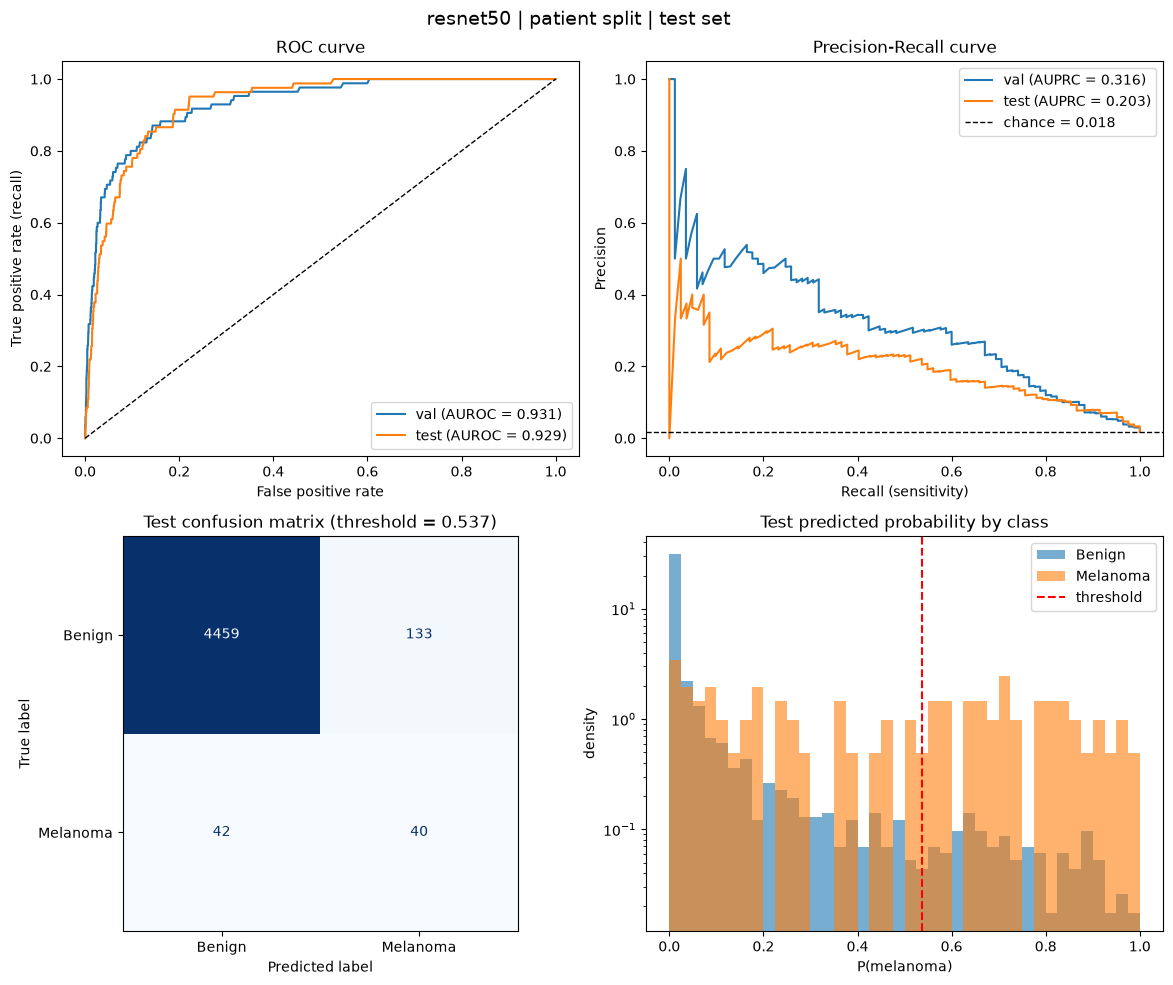

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, precision_recall_curve, auc,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)

yt_, pt_ = preds['test']
yv_, pv_ = preds['val']
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# ROC
for name, (y, p) in [('val', (yv_, pv_)), ('test', (yt_, pt_))]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0, 0].plot(fpr, tpr, label=f'{name} (AUROC = {auc(fpr, tpr):.3f})')
ax[0, 0].plot([0, 1], [0, 1], 'k--', lw=1)
ax[0, 0].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate (recall)')
ax[0, 0].legend()

# Precision-Recall
for name, (y, p) in [('val', (yv_, pv_)), ('test', (yt_, pt_))]:
    prec, rec, _ = precision_recall_curve(y, p)
    ax[0, 1].plot(rec, prec, label=f'{name} (AUPRC = {average_precision_score(y, p):.3f})')
ax[0, 1].axhline(yt_.mean(), color='k', ls='--', lw=1, label=f'chance = {yt_.mean():.3f}')
ax[0, 1].set(title='Precision-Recall curve', xlabel='Recall (sensitivity)', ylabel='Precision')
ax[0, 1].legend()

# Confusion matrix (test)
cm = confusion_matrix(yt_, (pt_ >= THRESHOLD).astype(int), labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Melanoma']).plot(ax=ax[1, 0], cmap='Blues', colorbar=False, values_format='d')
ax[1, 0].set_title(f'Test confusion matrix (threshold = {THRESHOLD:.3f})')

# Score distribution (test)
bins = np.linspace(0, 1, 41)
ax[1, 1].hist(pt_[yt_ == 0], bins=bins, alpha=0.6, label='Benign', density=True)
ax[1, 1].hist(pt_[yt_ == 1], bins=bins, alpha=0.6, label='Melanoma', density=True)
ax[1, 1].axvline(THRESHOLD, color='r', ls='--', label='threshold')
ax[1, 1].set(title='Test predicted probability by class', xlabel='P(melanoma)', ylabel='density', yscale='log')
ax[1, 1].legend()

plt.suptitle(f'{MODEL_NAME} | {SPLIT} split | test set', fontsize=14)
plt.tight_layout()
plt.savefig(RUN_DIR / 'test_diagrams.png', dpi=200, bbox_inches='tight')
plt.show()